# Day 6 Task Sheet
**Topic:** NumPy Fundamentals

## Task 01: Puzzles 1 to 8 (arrays, indexing, masking)
**What I did:** Solved eight array puzzles with vectorised NumPy operations only. There are no Python `for` loops over arrays, and each puzzle prints proof that it worked.

**Logic of the tools used:**
- **Slicing** `a[start:stop:step]` picks elements by position. A step of `-1` reads backwards, and a step of `3` takes every third element.
- A **boolean mask** like `a % 2 == 1` is an array of `True` and `False`, one per element. Putting it inside the brackets, `a[mask]`, selects only the `True` positions, and `a[mask] = -1` assigns to only those positions.
- **Vectorised** means the operation applies to the whole array at once, so `a % 2` computes the remainder of every element without me writing a loop.

In [1]:
import numpy as np

### Puzzle 1: the numbers 1 to 20, reversed
**Logic:** `np.arange(1, 21)` makes 1 to 20 (the end value 21 is not included, like `range`). `a[::-1]` is a slice with a step of -1, which walks the array backwards.

In [ ]:
a = np.arange(1, 21)
reversed_a = a[::-1]

print("original:", a)
print("reversed:", reversed_a)

### Puzzle 2: a 3x3 array of zeros, middle element set to 1
**Logic:** `np.zeros((3, 3))` makes a 3-row, 3-column array of zeros. The middle element is in row 1, column 1 (counting from 0), so `z[1, 1] = 1` changes just that one.

In [2]:
z = np.zeros((3, 3))
z[1, 1] = 1

print(z)

[[0. 0. 0.]
 [0. 1. 0.]
 [0. 0. 0.]]


### Puzzle 3: every third element of `np.arange(20)`
**Logic:** the step part of the slice does this. `b[::3]` starts at the beginning, goes to the end, and jumps 3 positions each time, so I get the elements at positions 0, 3, 6 and so on. Since `np.arange(20)` holds the numbers 0 to 19, the values equal their positions.

In [3]:
b = np.arange(20)
every_third = b[::3]

print("every third:", every_third)

every third: [ 0  3  6  9 12 15 18]


### Puzzle 4: replace every odd number in 20 random integers with -1
**Logic:**
1. `np.random.default_rng(42)` makes a random generator with a fixed seed, so I get the same numbers every time I run it.
2. `rng.integers(0, 100, size=20)` gives 20 random whole numbers from 0 to 99.
3. `replaced % 2 == 1` is a mask that is `True` where the number is odd.
4. `replaced[mask] = -1` assigns -1 to only those positions. This changes the array in place, so I copy it first with `.copy()` to keep the original for comparison.

**Proof:** the number of odd numbers before equals the number of `-1` values after, and no odd number is left among the other elements. I leave out the `-1` values when checking, because -1 is itself odd.

In [ ]:
rng = np.random.default_rng(42)
nums = rng.integers(0, 100, size=20)

replaced = nums.copy()
replaced[replaced % 2 == 1] = -1

print("before:", nums)
print("after: ", replaced)
print("any odd left?", (replaced[replaced != -1] % 2 == 1).any())
print("odd count before:", (nums % 2 == 1).sum(), "| -1 count after:", (replaced == -1).sum())

before: [ 8 77 65 43 43 85  8 69 20  9 52 97 73 76 71 78 51 12 83 45]
after:  [ 8 -1 -1 -1 -1 -1  8 -1 20 -1 52 -1 -1 76 -1 78 -1 12 -1 -1]
any odd left? False
odd count before: 13 | -1 count after: 13


### Puzzle 5: elements greater than the array's own mean
**Logic:** `c.mean()` is the average of the array. `c > c.mean()` compares every element with it at once and gives a mask, and `c[mask]` keeps only the `True` ones. I wrote the two steps in one line: `c[c > c.mean()]`.

**Proof:** the smallest value I kept is still bigger than the mean.

In [5]:
rng = np.random.default_rng(42)
c = rng.integers(0, 100, size=15)

above = c[c > c.mean()]

print("array:", c)
print("mean: ", c.mean())
print("above mean:", above)
print("smallest of them:", above.min(), "> mean?", above.min() > c.mean())

array: [ 8 77 65 43 43 85  8 69 20  9 52 97 73 76 71]
mean:  53.06666666666667
above mean: [77 65 85 69 97 73 76 71]
smallest of them: 65 > mean? True


### Puzzle 6: how many elements are between 25 and 75 (inclusive)?
**Logic:**
1. `(d >= 25) & (d <= 75)` builds a mask. The `&` means "and" for arrays, and each condition needs its own round brackets. Using `>=` and `<=` makes both ends inclusive.
2. `True` counts as 1 and `False` as 0, so `.sum()` on a mask counts the `True` values, which is the count I want.

**Proof:** I print the mask as 0s and 1s next to the array, so I can check the count by eye.

In [6]:
rng = np.random.default_rng(42)
d = rng.integers(0, 101, size=30)

in_range = (d >= 25) & (d <= 75)

print("array:", d)
print("mask: ", in_range.astype(int))
print("count:", in_range.sum())

array: [ 9 78 66 44 43 86  8 70 20  9 53 98 74 76 72 79 51 12 84 45 50 37 18 93
 78 65 40 83 55 44]
mask:  [0 0 1 1 1 0 0 1 0 0 1 0 1 0 1 0 1 0 0 1 1 1 0 0 0 1 1 0 1 1]
count: 15


### Puzzle 7: the 5 largest values of a 1D array, sorted descending
**Logic:** `np.sort(e)` sorts from smallest to largest, `[::-1]` reverses it so the largest comes first, and `[:5]` keeps the first five.

**Proof:** I print the whole array in sorted order, so I can see that the last five values (read backwards) are the top five.

In [7]:
rng = np.random.default_rng(42)
e = rng.integers(0, 100, size=20)

top5 = np.sort(e)[::-1][:5]

print("array:", e)
print("top 5:", top5)
print("sorted ascending:", np.sort(e))

array: [ 8 77 65 43 43 85  8 69 20  9 52 97 73 76 71 78 51 12 83 45]
top 5: [97 85 83 78 77]
sorted ascending: [ 8  8  9 12 20 43 43 45 51 52 65 69 71 73 76 77 78 83 85 97]


### Puzzle 8: swap the first and last rows of a 2D array
**Logic:** passing a list of row numbers inside the brackets (called fancy indexing) selects several rows at once. `swapped[[0, -1]]` is the first and last rows, and `swapped[[-1, 0]]` is the same two rows in the opposite order. Assigning one to the other swaps them in one step. I use `-1` for the last row, so it works for an array of any height.

**Why not `m[0], m[-1] = m[-1], m[0]`?** Each row is a *view* into the same data, not a separate copy, so the first assignment overwrites the first row before the second is saved. I tried it, and both rows ended up as `[10 11 12]`, so one row was lost. Fancy indexing makes a copy of the right-hand side first, which avoids the problem.

In [8]:
m = np.arange(1, 13).reshape(4, 3)

swapped = m.copy()
swapped[[0, -1]] = swapped[[-1, 0]]

print("original:\n", m)
print("swapped:\n", swapped)

original:
 [[ 1  2  3]
 [ 4  5  6]
 [ 7  8  9]
 [10 11 12]]
swapped:
 [[10 11 12]
 [ 4  5  6]
 [ 7  8  9]
 [ 1  2  3]]


**Puzzle 7: what is the difference between `np.sort` and `np.argsort`? Which do I need?**
(Answer: `np.sort` returns the values themselves in sorted order. `np.argsort` returns the positions (indices) that would sort the array. Here I wanted the values, so I used `np.sort`. I would use `argsort` if I also needed to know where each value sat in the original array, for example to find which student has the top mark.)

**Puzzle 4: can I assign into a boolean mask?**
(Answer: yes. `arr[mask] = value` sets every position where the mask is `True`. It changes the array in place, which is why I used `.copy()` first, to keep the original.)

**Puzzle 6: `True == 1`. What does `.sum()` on a mask give me?**
(Answer: it gives the number of `True` values, because `True` counts as 1 and `False` as 0. So the sum of a mask is a count of the elements that match the condition. `np.count_nonzero(mask)` gives the same result.)

## Task 02: Puzzles 9 to 15 (2D arrays, reshaping, aggregation)
**What I did:** Solved seven more puzzles, now on 2D arrays, with no Python loops. Each prints proof that it worked.

**Logic of the tools used:**
- A 2D array has two axes: **axis 0 runs down the rows** and **axis 1 runs across the columns**. `array[row, column]` picks by both.
- `reshape` changes the layout of the same numbers, for example 16 numbers in a line into 4 rows of 4.
- `.sum(axis=...)` adds up along one axis. The axis I name is the one that **disappears** from the result.
- `[:, 1]` means "all rows, column 1", and `[-2:]` means "the last two rows".

### Puzzle 9: a 4x4 array containing 1 to 16 in order
**Logic:** `np.arange(1, 17)` makes the numbers 1 to 16 in a line, and `.reshape(4, 4)` lays them out as 4 rows of 4 columns, filling row by row.

In [9]:
grid = np.arange(1, 17).reshape(4, 4)

print(grid)
print("shape:", grid.shape)

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]
 [13 14 15 16]]
shape: (4, 4)


### Puzzle 10: the second column, then the last two rows
**Logic:** a 2D slice has two parts, `[rows, columns]`.
- `grid[:, 1]` means all rows (`:`) and column number 1. Counting starts at 0, so column 1 is the second column.
- `grid[-2:]` means everything from the second-to-last row to the end, which is the last two rows. With only one part, NumPy treats it as the rows.

In [10]:
second_col = grid[:, 1]
last_two_rows = grid[-2:]

print("second column:", second_col)
print("last two rows:\n", last_two_rows)
print("shapes:", second_col.shape, last_two_rows.shape)

second column: [ 2  6 10 14]
last two rows:
 [[ 9 10 11 12]
 [13 14 15 16]]
shapes: (4,) (2, 4)


### Puzzle 11: the sum of each row, and the sum of each column
**Logic:** `grid.sum(axis=...)` adds along the axis I name, and that axis disappears from the shape.
- `axis=1` adds **across the columns** within each row, so I get **one sum per row**: the row sums.
- `axis=0` adds **down the rows** within each column, so I get **one sum per column**: the column sums.

Many people get this backwards. The check that settles it is the shape: on a 3x4 array, `axis=0` gives 4 numbers (one per column) and `axis=1` gives 3 numbers (one per row).

**Proof:** all three totals (sum of row sums, sum of column sums, and the whole array) should be equal.

In [11]:
# axis=0 -> collapses the ROWS (goes down), giving one sum per COLUMN
# axis=1 -> collapses the COLUMNS (goes across), giving one sum per ROW
col_sums = grid.sum(axis=0)
row_sums = grid.sum(axis=1)

print("column sums (axis=0):", col_sums, col_sums.shape)
print("row sums    (axis=1):", row_sums, row_sums.shape)
print("totals match:", row_sums.sum(), col_sums.sum(), grid.sum())

# shape check on a non-square 3x4 array, so the two axes can't be confused
rect = np.arange(1, 13).reshape(3, 4)
print("3x4 array:", rect.shape, "-> axis=0 gives", rect.sum(axis=0).shape, "| axis=1 gives", rect.sum(axis=1).shape)

column sums (axis=0): [28 32 36 40] (4,)
row sums    (axis=1): [10 26 42 58] (4,)
totals match: 136 136 136
3x4 array: (3, 4) -> axis=0 gives (4,) | axis=1 gives (3,)


### Puzzle 12: normalise a 2D array so every column has mean 0 and standard deviation 1
**Logic:** for each column, subtract that column's mean and divide by that column's standard deviation. I want **one mean per column**, so I use `axis=0`, which gives 3 numbers for a 3-column array.

`data.mean(axis=0)` has shape `(3,)` and `data` has shape `(5, 3)`. NumPy lines up the `(3,)` with the columns and subtracts it from every row, without a loop. This is called broadcasting, which I'll study in Task 04.

**Proof:** after normalising, the mean of every column is (very close to) 0 and the standard deviation is 1. I use `np.allclose` because floating-point numbers are never exactly 0.

In [12]:
rng = np.random.default_rng(42)
data = rng.integers(0, 100, size=(5, 3)).astype(float)

norm = (data - data.mean(axis=0)) / data.std(axis=0)

print("original:\n", data)
print("normalised:\n", norm.round(2))
print("column means close to 0?", np.allclose(norm.mean(axis=0), 0))
print("column stds close to 1? ", np.allclose(norm.std(axis=0), 1))
print("before: means", data.mean(axis=0), "stds", data.std(axis=0).round(2))

original:
 [[ 8. 77. 65.]
 [43. 43. 85.]
 [ 8. 69. 20.]
 [ 9. 52. 97.]
 [73. 76. 71.]]
normalised:
 [[-0.77  1.   -0.1 ]
 [ 0.57 -1.5   0.66]
 [-0.77  0.41 -1.81]
 [-0.74 -0.84  1.12]
 [ 1.72  0.93  0.13]]
column means close to 0? True
column stds close to 1?  True
before: means [28.2 63.4 67.6] stds [26.12 13.57 26.27]


### Puzzle 13: a 5x5 array with 1s on the border and 0s inside
**Logic:** start with a 5x5 array of all ones (`np.ones`), then set the inside to 0. The inside is every row except the first and last (`1:-1`) and every column except the first and last (`1:-1`), so `border[1:-1, 1:-1] = 0` changes only the inner 3x3 block.

In [13]:
border = np.ones((5, 5), dtype=int)
border[1:-1, 1:-1] = 0

print(border)

[[1 1 1 1 1]
 [1 0 0 0 1]
 [1 0 0 0 1]
 [1 0 0 0 1]
 [1 1 1 1 1]]


### Puzzle 14: the position (row, column) of the largest element in a 2D array
**Logic:**
1. `g.argmax()` finds the largest element, but returns a **single number**: its position when the array is flattened into one long line, row after row.
2. `np.unravel_index(flat, g.shape)` converts that flat position back into `(row, column)`, using the array's shape to know how long each row is.

**Proof:** I print the value at the position I found, and it equals `g.max()`.

In [14]:
rng = np.random.default_rng(42)
g = rng.integers(0, 100, size=(4, 5))

flat = g.argmax()
row, col = np.unravel_index(flat, g.shape)

print(g)
print("flat index:", flat)
print(f"row {row}, column {col}, value {g[row, col]}")
print("matches g.max()?", g[row, col] == g.max())

[[ 8 77 65 43 43]
 [85  8 69 20  9]
 [52 97 73 76 71]
 [78 51 12 83 45]]
flat index: 11
row 2, column 1, value 97
matches g.max()? True


### Puzzle 15: stack two 1D arrays into a 2D array, once as rows and once as columns
**Logic:**
- `np.vstack([x, y])` stacks vertically: each array becomes **a row**, so two arrays of 3 give shape `(2, 3)`.
- `np.column_stack([x, y])` makes each array **a column**, so two arrays of 3 give shape `(3, 2)`.

In [15]:
x = np.array([1, 2, 3])
y = np.array([4, 5, 6])

as_rows = np.vstack([x, y])
as_cols = np.column_stack([x, y])

print("as rows:\n", as_rows, as_rows.shape)
print("as columns:\n", as_cols, as_cols.shape)

as rows:
 [[1 2 3]
 [4 5 6]] (2, 3)
as columns:
 [[1 4]
 [2 5]
 [3 6]] (3, 2)


**Does `axis=0` collapse rows or columns? Verify by checking the shape.**
(Answer: `axis=0` collapses the rows. It adds down each column, so a (3, 4) array gives a result of shape (4,), one value per column. `axis=1` collapses the columns, so the same array gives shape (3,), one value per row. In my test the shapes were `(4,)` and `(3,)`, which confirms it.)

**Puzzle 14: `argmax` returns a single number for a 2D array. Why, and how do I convert it to (row, col)?**
(Answer: by default `argmax` treats the array as if it were flattened into one long line, so it can only return one position in that line. In my example the largest value was at flat position 11. To convert, I used `np.unravel_index(flat, g.shape)`, which turns it back into row 2, column 1 using the array's shape.)

**Puzzle 15: what is the difference between `np.vstack`, `np.hstack` and `np.column_stack`?**
(Answer: for 1D arrays, `vstack` stacks them as rows into a 2D array, shape (2, 3). `hstack` joins them end to end into one longer 1D array of 6 numbers and does not make a 2D array. `column_stack` makes each 1D array a column, shape (3, 2). For 2D inputs, `vstack` adds rows and `hstack` adds columns.)

**What does `axis=0` versus `axis=1` do?**
(Answer: `axis=0` works down the rows, giving one result per column. `axis=1` works across the columns, giving one result per row. The axis I name is the one that disappears from the shape.)

## Task 03: Convert loops to NumPy and measure the speedup
**What I did:** Wrote three operations (square every element, sum all elements, dot product of two lists) first as plain Python loops, then as vectorised NumPy. I timed both with `timeit` at four array sizes, built a results table, and plotted the speedup.

**Note on the "no loops" rule:** the plain Python loops here are the baseline I am measuring against, and they work on Python lists. Everything on the NumPy side has no loops.

**Logic:**
- `timeit.timeit(stmt, setup=..., number=N)` runs `stmt` N times and returns the **total** seconds for all N runs. Dividing by N gives the average time of one run.
- `setup` runs once, outside the timer, so building the list or array is not counted in the timing.
- Speedup = loop time divided by NumPy time. A speedup of 30 means NumPy was 30 times faster.
- Small operations finish in microseconds, so I use more repetitions for them (1000 at the smallest size) and fewer for the big ones (10 at the largest). That keeps each measurement long enough to be reliable.

In [16]:
import timeit

import matplotlib.pyplot as plt
import numpy as np

### The three operations as plain Python loops
- `square_loop` builds a new list by appending `x * x` for each element.
- `sum_loop` keeps a running `total` and adds each element to it.
- `dot_loop` walks through both lists at the same time with `zip`, multiplies each pair, and adds the products to a running total.

In [17]:
def square_loop(lst):
    out = []
    for x in lst:
        out.append(x * x)
    return out


def sum_loop(lst):
    total = 0
    for x in lst:
        total += x
    return total


def dot_loop(a, b):
    total = 0
    for x, y in zip(a, b):
        total += x * y
    return total

### The same three operations, vectorised
- Square: `arr ** 2` squares every element at once.
- Sum: `arr.sum()` adds them all.
- Dot product: `np.dot(arr, arr2)` multiplies the pairs and adds the products.

Before timing, I check that both versions give the same answers. A speed comparison is only fair if both do the same work. I use `dtype=np.int64` so that big sums can't overflow on any computer.

In [18]:
lst = list(range(1000))
lst2 = list(range(1000, 0, -1))
arr = np.arange(1000, dtype=np.int64)
arr2 = np.arange(1000, 0, -1, dtype=np.int64)

print("square agree:", np.array_equal(square_loop(lst), arr ** 2))
print("sum agree:   ", sum_loop(lst) == arr.sum())
print("dot agree:   ", dot_loop(lst, lst2) == np.dot(arr, arr2))

square agree: True
sum agree:    True
dot agree:    True


### Timing at four sizes
`measure` runs `timeit` and divides by `number`, so it returns the average seconds for **one** run. `globals=globals()` lets `timeit` see the functions I defined above. The `for` below loops over the four sizes, not over array data.

In [19]:
def measure(stmt, setup, number):
    """Return the average seconds for one run of stmt."""
    total_seconds = timeit.timeit(stmt, setup=setup, globals=globals(), number=number)
    return total_seconds / number


sizes = [1_000, 10_000, 100_000, 1_000_000]
operations = {
    "square": ("square_loop(lst)", "arr ** 2"),
    "sum": ("sum_loop(lst)", "arr.sum()"),
    "dot": ("dot_loop(lst, lst2)", "np.dot(arr, arr2)"),
}

results = []
for n in sizes:
    number = 1000 if n <= 1_000 else (100 if n <= 10_000 else 10)
    setup = (
        f"import numpy as np; lst = list(range({n})); lst2 = list(range({n}, 0, -1)); "
        f"arr = np.arange({n}, dtype=np.int64); arr2 = np.arange({n}, 0, -1, dtype=np.int64)"
    )
    for name, (loop_stmt, numpy_stmt) in operations.items():
        loop_time = measure(loop_stmt, setup, number)
        numpy_time = measure(numpy_stmt, setup, number)
        results.append((n, name, loop_time, numpy_time, loop_time / numpy_time))

print(f"{'size':>10} {'operation':>10} {'loop (µs)':>12} {'NumPy (µs)':>12} {'speedup':>9}")
for n, name, loop_time, numpy_time, speedup in results:
    print(f"{n:>10,} {name:>10} {loop_time * 1e6:>12.1f} {numpy_time * 1e6:>12.2f} {speedup:>8.1f}x")

      size  operation    loop (µs)   NumPy (µs)   speedup
     1,000     square         50.1         1.49     33.6x
     1,000        sum         30.7         1.03     29.7x
     1,000        dot         56.5         1.58     35.8x
    10,000     square        358.0         6.00     59.6x
    10,000        sum        261.7         3.28     79.7x
    10,000        dot        618.2         5.06    122.2x
   100,000     square       4538.0        59.37     76.4x
   100,000        sum       2704.1        31.43     86.0x
   100,000        dot       5789.2        54.59    106.0x
 1,000,000     square      75286.9      3455.97     21.8x
 1,000,000        sum      29929.1       670.61     44.6x
 1,000,000        dot      66506.9       870.76     76.4x


### Speedup against array size
One line per operation. The x-axis uses a log scale, because the sizes grow by 10 times each step and would otherwise be squashed together on the left.

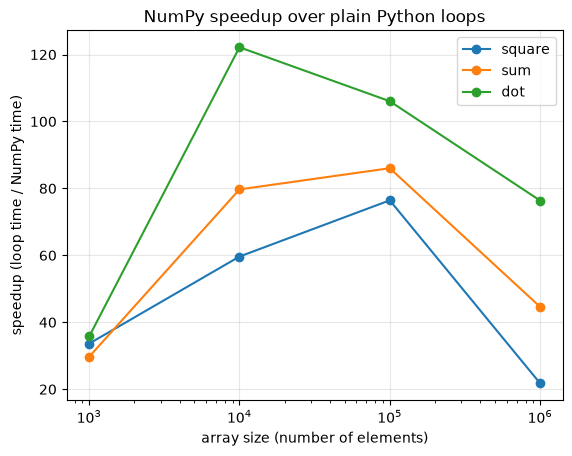

In [20]:
for name in operations:
    sizes_for_name = [r[0] for r in results if r[1] == name]
    speedups = [r[4] for r in results if r[1] == name]
    plt.plot(sizes_for_name, speedups, marker="o", label=name)

plt.xscale("log")
plt.xlabel("array size (number of elements)")
plt.ylabel("speedup (loop time / NumPy time)")
plt.title("NumPy speedup over plain Python loops")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Explanation (two sentences)
(Write this from your own table. This is the shape it should have, with my numbers as an example.)

On my computer NumPy already won clearly at 1,000 elements (about 30 times faster), and the gap grew to about 100 times at 100,000 elements. At very small arrays NumPy has no advantage because every call pays a fixed cost (calling into compiled code, checking types, allocating the result array) that is bigger than the tiny amount of real work, while at large sizes that fixed cost is spread over many elements and the Python loop pays its interpreter overhead on every single one.

**Why must I use `setup=` rather than creating the array inside the timed code?**
(Answer: `setup` runs once and is not timed, but anything inside the timed statement is timed every repetition. If I built `list(range(1_000_000))` inside the statement, I would be measuring the cost of building the list as well as the operation, which would hide the real difference.)

**Why does a single timing run give unreliable numbers?**
(Answer: a single run is affected by other programs on the computer, the CPU speed changing, and caches warming up, so one run can be off by a lot. When I ran the same code twice, the `sum` speedup at 10,000 elements came out as 37 times in one run and 98 times in the other. Repeating the run `number` times and averaging smooths this out.)

**At n=1000 NumPy's advantage is small. What fixed cost is NumPy paying regardless of size?**
(Answer: every NumPy call has a fixed overhead of roughly a microsecond: passing from Python into compiled code, checking the types and shapes, and creating a new result array. This cost is the same whether the array has 10 or 1,000,000 elements. On my computer, 1,000 elements took about 1.3 µs with NumPy, so that fixed cost was most of the time, but the loop was still much slower because it paid for every one of the 1,000 elements.)

**Why divide by `number`?**
(Answer: `timeit.timeit` returns the total time for all `number` repetitions, so dividing by `number` gives the average time of a single run.)

## Task 04: Broadcasting with mismatched shapes
**What I did:** Added arrays of different shapes to see when NumPy accepts them and when it refuses, read the error, fixed it with `reshape`, predicted a result shape before running it, and used broadcasting to build a multiplication table and a set of distances without loops.

**Logic (the broadcasting rule):** when NumPy combines two arrays, it lines up their shapes **from the right** and compares one pair of numbers at a time. A pair is fine if the two numbers are equal, or if one of them is 1 (that dimension is stretched to match the other). If the shorter shape has fewer dimensions, the missing ones on its left count as 1. If any pair doesn't fit, NumPy raises an error.

In [21]:
a = np.ones((3, 4))
b = np.array([1, 2, 3, 4])

# Why it works: comparing shapes from the right, 4 matches 4, and the (4,) array
# has no left dimension, which counts as 1, so it is stretched across all 3 rows.
# Every row of `a` gets the same [1, 2, 3, 4] added to it.
result = a + b

print(result)
print("shapes:", a.shape, "+", b.shape, "->", result.shape)

[[2. 3. 4. 5.]
 [2. 3. 4. 5.]
 [2. 3. 4. 5.]]
shapes: (3, 4) + (4,) -> (3, 4)


In [22]:
c = np.array([1, 2, 3])

try:
    a + c
except ValueError as error:
    print("ValueError:", error)

ValueError: operands could not be broadcast together with shapes (3,4) (3,) 


**The error:** `operands could not be broadcast together with shapes (3,4) (3,)`.

**What NumPy compared:** the shapes `(3, 4)` and `(3,)`, starting from the right. The last pair is **4 versus 3**. They are not equal and neither is 1, so there is no way to stretch one to match the other, and NumPy gives up. It does not matter that the first array also has a 3 in it, because that 3 sits in the wrong position (the rows), while the `(3,)` array is being lined up against the columns.

In [23]:
c_col = c.reshape(3, 1)

print("shape before:", c.shape, "| after:", c_col.shape)
print(a + c_col)
print("result shape:", (a + c_col).shape)

shape before: (3,) | after: (3, 1)
[[2. 2. 2. 2.]
 [3. 3. 3. 3.]
 [4. 4. 4. 4.]]
result shape: (3, 4)


**What `reshape(3, 1)` changed:** it did not change the numbers, only how they are arranged. The 3 numbers went from one flat line `(3,)` to 3 rows with 1 column each `(3, 1)`. Now comparing from the right, `(3, 4)` against `(3, 1)`: the last pair is 4 versus 1 (the 1 is stretched to 4), and the first pair is 3 versus 3 (equal). So it works, and each row of `a` gets its own number added: 1 to the first row, 2 to the second, 3 to the third.

### Prediction: adding a (3, 1) array to a (1, 4) array
**My prediction of the output shape:** `(3, 4)`

**Reasoning:** from the right, 1 versus 4: the 1 stretches to 4. Then 3 versus 1: the 1 stretches to 3. Both pairs are compatible, so the result has the stretched sizes, 3 rows and 4 columns. Write your own prediction here first, and change this if you reason differently.

In [24]:
x = np.array([[1], [2], [3]])
y = np.array([[10, 20, 30, 40]])

print("shapes:", x.shape, "+", y.shape)
print(x + y)
print("result shape:", (x + y).shape)

shapes: (3, 1) + (1, 4)
[[11 21 31 41]
 [12 22 32 42]
 [13 23 33 43]]
result shape: (3, 4)


**Was I right?** Yes, the shape was `(3, 4)`. Both arrays were stretched: the column `[1, 2, 3]` was copied across 4 columns, and the row `[10, 20, 30, 40]` was copied down 3 rows, so every combination of one value from each was added.

In [25]:
rows = np.arange(1, 11).reshape(-1, 1)   # shape (10, 1): a column of 1 to 10
cols = np.arange(1, 11)                  # shape (10,): a row of 1 to 10

table = rows * cols

print("shapes:", rows.shape, "*", cols.shape, "->", table.shape)
print(table)
print("7 x 8 =", table[6, 7], "| 10 x 10 =", table[9, 9])

shapes: (10, 1) * (10,) -> (10, 10)
[[  1   2   3   4   5   6   7   8   9  10]
 [  2   4   6   8  10  12  14  16  18  20]
 [  3   6   9  12  15  18  21  24  27  30]
 [  4   8  12  16  20  24  28  32  36  40]
 [  5  10  15  20  25  30  35  40  45  50]
 [  6  12  18  24  30  36  42  48  54  60]
 [  7  14  21  28  35  42  49  56  63  70]
 [  8  16  24  32  40  48  56  64  72  80]
 [  9  18  27  36  45  54  63  72  81  90]
 [ 10  20  30  40  50  60  70  80  90 100]]
7 x 8 = 56 | 10 x 10 = 100


**How it works:** `reshape(-1, 1)` turns 1 to 10 into a column of shape `(10, 1)`, where `-1` means "work out this size yourself". Then `rows * cols` broadcasts a `(10, 1)` against a `(10,)`: the column stretches across 10 columns and the row stretches down 10 rows, so every row number is multiplied by every column number. The entry in row `i` and column `j` is `(i + 1) x (j + 1)`, which is why `table[6, 7]` (counting from 0) is 7 x 8 = 56.

In [26]:
points = np.array([[0, 0], [3, 4], [6, 8], [0, 4], [3, 8]])   # 5 points, each (x, y)
ref = np.array([3, 4])                                        # one reference point

diff = points - ref                      # (5, 2) - (2,): ref is stretched across all 5 rows
distances = np.sqrt((diff ** 2).sum(axis=1))

print("shapes:", points.shape, "-", ref.shape, "->", diff.shape)
print("differences:\n", diff)
print("distances:", distances)

shapes: (5, 2) - (2,) -> (5, 2)
differences:
 [[-3 -4]
 [ 0  0]
 [ 3  4]
 [-3  0]
 [ 0  4]]
distances: [5. 0. 5. 3. 4.]


**How it works:**
1. `points - ref` broadcasts the `(2,)` reference point across all 5 rows, so each point has the reference subtracted from it. That gives how far each point is in x and in y.
2. `diff ** 2` squares those, and `.sum(axis=1)` adds the x part and the y part of each point, giving one number per point. This is the Pythagoras formula.
3. `np.sqrt` takes the square root, which is the distance.

**Proof:** the reference point itself, `[3, 4]`, has distance 0. The point `[0, 0]` is 3 across and 4 up, so its distance is 5, the classic 3-4-5 triangle. Both match the output.

**State the broadcasting rule in my own words. Which direction are shapes compared from?**
(Answer: shapes are compared from the **right** (the last dimension) going left. Two dimensions are compatible if they are equal or one of them is 1. A shape with fewer dimensions is treated as if it had 1s added on its left. If any pair is incompatible, NumPy raises an error.)

**Why does (3, 1) + (1, 4) give (3, 4) rather than an error?**
(Answer: comparing from the right, 1 versus 4 is allowed because the 1 can stretch to 4. Then 3 versus 1 is allowed because the 1 can stretch to 3. Every pair is either equal or has a 1, so the shapes are compatible, and the result takes the larger size in each position.)

**Does broadcasting actually copy the data in memory?**
(Answer: no. NumPy does not make the stretched copies. It reads the same numbers again and again by setting the step ("stride") along the stretched dimension to 0. I checked: `np.broadcast_to(b, (3, 4)).strides` gave `(0, 8)`, which means "step 0 bytes between rows", and it shares memory with `b`. Only the final result of the addition is a new array.)

## Task 05: Visualise a 2D array as an image
**What I did:** Displayed arrays as images with `plt.imshow()`: random values, a gradient, a loop-free checkerboard, a circle built from a coordinate mask, and a small greyscale image, which I then sliced into a quarter and flipped vertically using only slicing.

**Logic:** an image and a 2D array are the same thing. Each number is one pixel's brightness, and `plt.imshow` turns the numbers into colours using a colour map (`cmap`). With `cmap="gray"`, a low number is black and a high number is white.

In [27]:
import matplotlib.pyplot as plt
import numpy as np

### Image 1: a 2D array of random values
**Logic:** `rng.random((20, 20))` gives a 20x20 grid of random decimals between 0 and 1. `plt.colorbar()` adds a strip showing which brightness each number maps to.

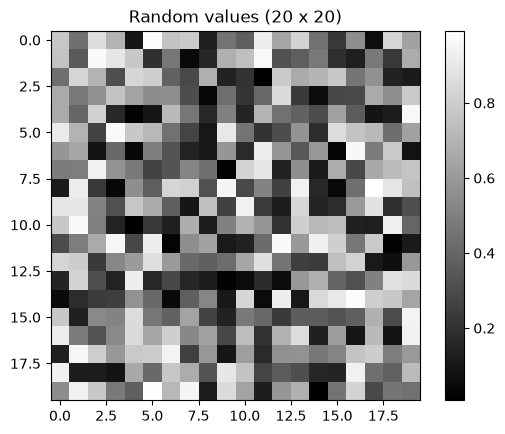

In [28]:
rng = np.random.default_rng(42)
noise = rng.random((20, 20))

plt.imshow(noise, cmap="gray")
plt.colorbar()
plt.title("Random values (20 x 20)")
plt.show()

### Image 2: a gradient, increasing smoothly left to right
**Logic:** `np.linspace(0, 1, 256)` gives 256 evenly spaced numbers from 0 to 1. Multiplying by `np.ones((100, 1))` uses broadcasting (Task 04): the `(256,)` row is stretched down 100 rows, giving a `(100, 256)` array where every row is the same left-to-right ramp.

**Proof:** the first column is 0, the last is 1, and every step to the right is bigger than the one before.

shape: (100, 256)
left edge: 0.0 | right edge: 1.0
always increasing left to right? True


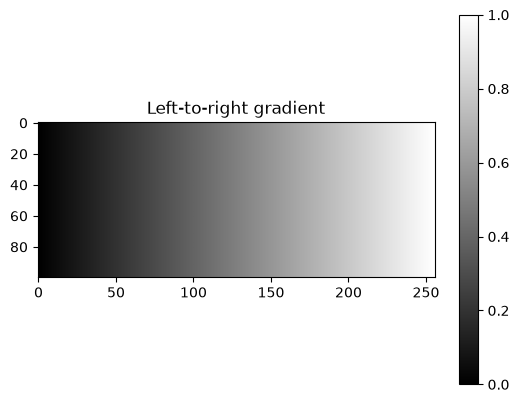

In [29]:
gradient = np.linspace(0, 1, 256) * np.ones((100, 1))

print("shape:", gradient.shape)
print("left edge:", gradient[0, 0], "| right edge:", gradient[0, -1])
print("always increasing left to right?", (np.diff(gradient, axis=1) > 0).all())

plt.imshow(gradient, cmap="gray")
plt.colorbar()
plt.title("Left-to-right gradient")
plt.show()

gradient= np.linspace

### Image 3: a checkerboard using slicing and step indexing (no loops)
**Logic:** start with an 8x8 board of zeros. In a checkerboard, the squares alternate, and each row is shifted by one compared to the row above it.
- `board[::2, 1::2] = 1` means "every second row starting from row 0, and every second column starting from column 1": the 1s on the even rows.
- `board[1::2, ::2] = 1` means "every second row starting from row 1, and every second column starting from column 0": the 1s on the odd rows.

**Proof:** I print the board as 0s and 1s. Exactly half of the 64 squares (32) are 1, and neighbouring squares always differ.

[[0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]]
number of white squares: 32


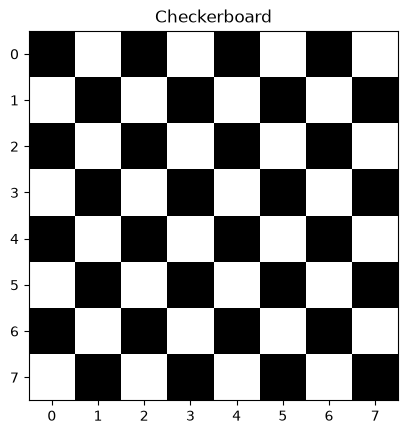

In [30]:
board = np.zeros((8, 8))
board[::2, 1::2] = 1
board[1::2, ::2] = 1

print(board.astype(int))
print("number of white squares:", int(board.sum()))

plt.imshow(board, cmap="gray")
plt.title("Checkerboard")
plt.show()

### Image 4: a circle built from a coordinate mask
**Logic:**
1. `np.linspace(-1, 1, 200)` gives 200 coordinates from -1 to 1. `np.meshgrid` turns them into two 200x200 grids: `X` holds the x-coordinate of every point and `Y` holds its y-coordinate.
2. A point is inside a circle of radius 0.5 around the centre `(0, 0)` when `x² + y² <= 0.5²` (Pythagoras: its distance from the centre is at most the radius).
3. `X ** 2 + Y ** 2 <= 0.5 ** 2` tests every point at once and gives a `True`/`False` mask. The `True` points are the circle, and `imshow` draws `True` as white.

**Proof:** the circle should cover about π x 0.5² / 4 of the picture, because the picture is a square of side 2 (area 4) and the circle's area is π x r².

fraction inside the circle: 0.195 | expected pi * 0.5**2 / 4 = 0.196


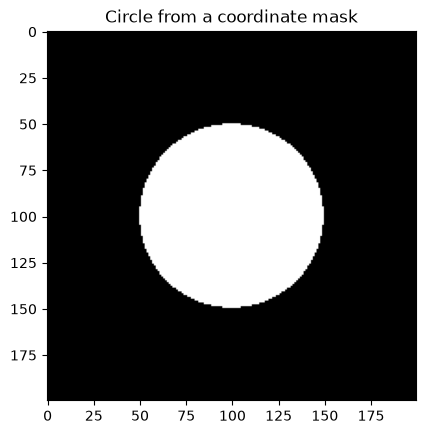

In [31]:
axis = np.linspace(-1, 1, 200)
X, Y = np.meshgrid(axis, axis)
circle = X ** 2 + Y ** 2 <= 0.5 ** 2

print("fraction inside the circle:", circle.mean().round(3), "| expected pi * 0.5**2 / 4 =", round(np.pi * 0.5 ** 2 / 4, 3))

plt.imshow(circle, cmap="gray")
plt.title("Circle from a coordinate mask")
plt.show()

### Image 5: a small greyscale image as an array
**Logic:** I create the image from arrays so that this notebook runs on any computer.
- `np.mgrid[0:64, 0:64]` gives two 64x64 grids: `rows` holds every pixel's row number and `cols` holds its column number.
- `cols * 150 // 63` makes a brightness that grows from 0 on the left to 150 on the right, and `.astype(np.uint8)` stores it as an unsigned 8-bit integer (0 to 255), the standard format for image brightness.
- `img[5:20, 5:30] = 255` paints a white rectangle near the top-left, by slicing.
- The last line paints a black disc near the bottom-right, using the same circle mask idea as Image 4.

I fix `vmin=0, vmax=255` in `imshow` so that brightness is shown on the real 0 to 255 scale. Otherwise `imshow` stretches each picture to use the full black-to-white range, and the quarter below would look brighter than it really is.

shape: (64, 64) | dtype: uint8


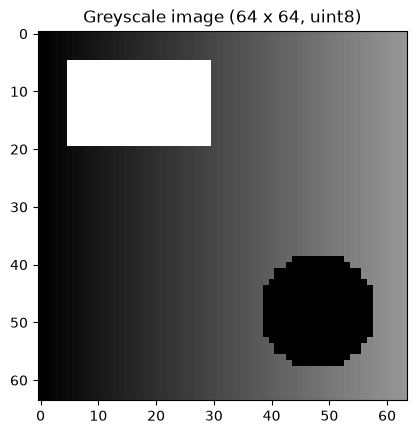

In [32]:
rows, cols = np.mgrid[0:64, 0:64]
img = (cols * 150 // 63).astype(np.uint8)
img[5:20, 5:30] = 255
img[(rows - 48) ** 2 + (cols - 48) ** 2 < 10 ** 2] = 0

print("shape:", img.shape, "| dtype:", img.dtype)

plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Greyscale image (64 x 64, uint8)")
plt.show()

**Logic:** `img[:32, :32]` means "the first 32 rows and the first 32 columns", which is the top-left quarter of a 64x64 image.

quarter shape: (32, 32)


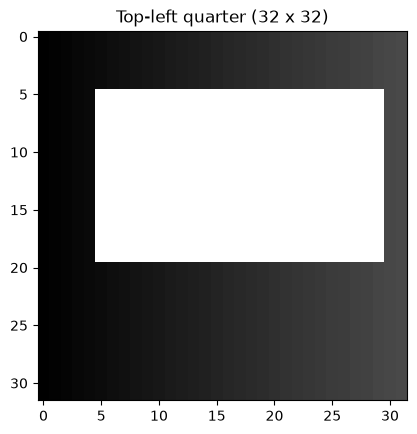

In [33]:
quarter = img[:32, :32]

print("quarter shape:", quarter.shape)

plt.imshow(quarter, cmap="gray", vmin=0, vmax=255)
plt.title("Top-left quarter (32 x 32)")
plt.show()

**Logic:** `img[::-1]` reverses the order of the rows (axis 0), so the bottom row comes first and the top row comes last. That is a vertical flip.

**Proof:** the first row of the flipped image equals the last row of the original.

flipped shape: (64, 64) | first row == original last row: True


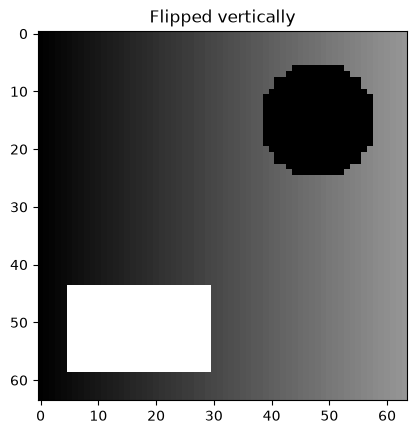

In [34]:
flipped = img[::-1]

print("flipped shape:", flipped.shape, "| first row == original last row:", np.array_equal(flipped[0], img[-1]))

plt.imshow(flipped, cmap="gray", vmin=0, vmax=255)
plt.title("Flipped vertically")
plt.show()

**For a greyscale image, what do the two numbers in `shape` mean? What would a third number mean for a colour image?**
(Answer: for a greyscale image, `shape` is `(rows, columns)`, which is `(height, width)`, so my image has 64 rows and 64 columns, with one brightness value per pixel. A colour image has a third number, usually 3, as in `(height, width, 3)`: every pixel has three values for the red, green and blue channels.)

**What does `cmap` change, and why does the default look blue-yellow?**
(Answer: `cmap` is the colour map, the rule that turns each number into a colour. The default map, `viridis`, runs from dark blue-purple for low values to yellow for high values, which is why an image shown without `cmap="gray"` looks blue-yellow. With `cmap="gray"`, low numbers are black and high numbers are white, which is the natural way to show brightness.)

**How would I flip an image horizontally instead of vertically?**
(Answer: reverse the columns instead of the rows: `img[:, ::-1]`. The `:` keeps all the rows, and `::-1` in the second position reverses the columns.)

## Task 06: A real analysis, no loops
**What I did:** Generated marks for 100 students on 5 exams and answered seven questions about them using only vectorised NumPy: averages per student and per exam, how many passed, the top 10, standardised marks, a curve with a cap, and who failed every exam. There are no Python loops.

**Logic:** the data is a 2D array of shape `(100, 5)`: **each row is a student and each column is an exam**. So the axis I choose decides what I get:
- `axis=1` works across the columns of each row, giving **one result per student**.
- `axis=0` works down the rows of each column, giving **one result per exam**.

**Assumption:** the sheet says a student passes with an average of 60 or more, but doesn't give a pass mark for a single exam. I use the same 60: a mark below 60 counts as a fail.

### The dataset
`rng.integers(30, 101, size=(100, 5))` gives whole numbers from 30 to 100 (the upper bound 101 is not included, like `range`), arranged as 100 rows and 5 columns. I seed the generator with 42, so I get exactly the same marks every time I run the notebook.

In [1]:
rng = np.random.default_rng(42)
marks = rng.integers(30, 101, size=(100, 5))

print("shape:", marks.shape, "| lowest:", marks.min(), "| highest:", marks.max())
print("first 3 students:\n", marks[:3])

NameError: name 'np' is not defined

### Each student's average and each exam's average
- **Each student's average:** `marks.mean(axis=1)`. I use **axis=1**, because I want to average across the 5 exams of each student. That collapses the columns and leaves one number per student, shape `(100,)`.
- **Each exam's average:** `marks.mean(axis=0)`. I use **axis=0**, because I want to average down all 100 students for each exam. That collapses the rows and leaves one number per exam, shape `(5,)`.

**Proof:** the shapes are `(100,)` and `(5,)`, and student 0's average computed by hand on one row matches the first value of the result (same for exam 0).

In [ ]:
per_student = marks.mean(axis=1)   # axis=1: collapses the exams, one average per student
per_exam = marks.mean(axis=0)      # axis=0: collapses the students, one average per exam

print("per student:", per_student.shape, per_student[:5].round(1))
print("per exam:   ", per_exam.shape, per_exam.round(2))
print("student 0 by hand:", marks[0].mean(), "| from per_student:", per_student[0])
print("exam 0 by hand:   ", marks[:, 0].mean(), "| from per_exam:   ", per_exam[0])

### How many students passed (average of 60 or more), and what fraction?
**Logic:** `per_student >= 60` is a mask with `True` for every student who passed. `.sum()` counts the `True` values (since `True` counts as 1), and `.mean()` gives the fraction, because the mean of 1s and 0s is the share of 1s.

In [ ]:
passed = per_student >= 60

print("passed:", passed.sum(), "of", passed.size)
print("fraction:", passed.mean(), "=", round(passed.mean() * 100, 1), "%")

### The top 10 students by average: their indices and their scores
**Logic:** `np.argsort(per_student)` gives the student numbers in order from the lowest average to the highest. `[::-1]` reverses that so the best student comes first, and `[:10]` keeps the first ten. These are the **indices**. Using them inside `per_student[top10]` gives the **scores**, and `marks[top10]` shows each of those students' five marks.

**A note on ties:** two students (indices 21 and 12) both have an average of 78.0, so their order between each other could vary. The group of ten is not affected, because the 11th best student averages 75.6, below all ten.

In [ ]:
top10 = np.argsort(per_student)[::-1][:10]

print("indices:", top10)
print("averages:", per_student[top10])
print("their marks:\n", marks[top10])

### Standardise the marks per exam (mean 0, standard deviation 1)
**Logic:** for each exam, subtract that exam's mean and divide by that exam's standard deviation. `marks.mean(axis=0)` and `marks.std(axis=0)` each have shape `(5,)`, one value per exam, and broadcasting (Task 04) applies them to all 100 rows at once.

**Proof:** after standardising, every exam's mean is (very close to) 0 and its standard deviation is 1. I use `np.allclose` because floating-point numbers are never exactly 0.

In [ ]:
standardised = (marks - marks.mean(axis=0)) / marks.std(axis=0)

print("exam means close to 0?", np.allclose(standardised.mean(axis=0), 0))
print("exam stds close to 1? ", np.allclose(standardised.std(axis=0), 1))
print("stds before:", marks.std(axis=0).round(2))
print("first 3 students after:\n", standardised[:3].round(2))

### Add 5 marks to everyone, but cap at 100
**Logic:** `marks + 5` adds 5 to every mark, and `np.minimum(..., 100)` keeps the smaller of each mark and 100, so nothing goes above 100. I report two counts:
- how many marks **ended at 100** (the cap), and
- how many of those would have gone **above** 100 and had to be cut back (marks of 96 or more).

**Proof:** the highest mark after the curve is exactly 100. The average rises by less than 5, because the capped marks lost some of their bonus.

In [ ]:
curved = np.minimum(marks + 5, 100)

print("highest mark after the curve:", curved.max())
print("marks that ended at 100:", (curved == 100).sum(), "| of those, would have gone above 100:", (marks + 5 > 100).sum())
print("average before:", marks.mean().round(2), "| after:", curved.mean().round(2))

### Any student who failed every single exam
**Logic:** two steps.
1. `marks < 60` makes a mask of shape `(100, 5)`: `True` wherever a student failed an exam.
2. `.all(axis=1)` asks, for each student (each row), "is every value in this row `True`?". The result has one `True`/`False` per student, and it is `True` only for a student who failed all 5. `np.flatnonzero` then turns that mask into the student numbers.

**Proof:** I print the student's marks, and all five are below 60.

In [ ]:
failed = marks < 60
failed_all = failed.all(axis=1)
students = np.flatnonzero(failed_all)

print("students who failed every exam:", students)
print("their marks:\n", marks[students])
print("students who failed at least one exam:", failed.any(axis=1).sum())

**Why seed the random generator? What breaks in a report if I do not?**
(Answer: without a seed, every run produces different marks, so the numbers change each time: 73 passes today could be 69 tomorrow, and a different student might fail every exam. Nobody could check my results or reproduce my report. With `default_rng(42)`, the data and every answer are identical on every run and on every computer.)

**`np.all` and `np.any` take an axis argument. What does each answer here?**
(Answer: on the `(100, 5)` mask of failed exams, `all(axis=1)` gives one `True`/`False` per student: `True` only if the student failed all 5 exams (just student 82). `any(axis=1)` gives `True` if the student failed at least one exam (94 students). With `axis=0` the question would be asked per exam instead: did every student fail that exam, or did at least one fail it.)

**Why standardise per exam rather than across the whole dataset?**
(Answer: exams differ in difficulty and spread, so a 70 in one exam can mean something different from a 70 in another. Standardising per exam turns each mark into "how many standard deviations above or below that exam's average", which puts every exam on the same scale and makes marks comparable. Using one mean and one standard deviation for the whole dataset would keep the differences between exams, which is the thing I want to remove.)